<a href="https://colab.research.google.com/github/dldustj0715/machine_learning/blob/main/week08/mobile_battery_power_dl_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mobile Battery Power Prediction — Deep Learning Regression


## 1. Google Drive 연결 및 데이터 불러오기

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)
path = '/content/drive/MyDrive/Colab Notebooks/mobile.csv'
df = pd.read_csv(path)
print('데이터 크기:', df.shape)
display(df.head())
print('결측치:', df.isna().sum().sum())

Mounted at /content/drive
데이터 크기: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


결측치: 0


## 2. 입력 특성(X)과 정답(y) 분리
`battery_power`는 예측 대상이므로 입력에서 제외한다. `price_range`는 별도 가격 등급 레이블이므로 제외한다.

In [2]:
X = df.drop(columns=['battery_power', 'price_range'])
y = df['battery_power']
print('X:', X.shape, 'y:', y.shape)

X: (2000, 19) y: (2000,)


## 3. 학습/테스트 분리 및 표준화
테스트 데이터 정보가 학습에 섞이지 않도록 학습 데이터로만 scaler를 학습한다.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print('학습:', X_train.shape, '테스트:', X_test.shape)

학습: (1600, 19) 테스트: (400, 19)


## 4. 딥러닝 모델 생성
회귀 출력층은 활성화 함수를 지정하지 않는다. (`linear`와 동일).

In [4]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

## 5. 컴파일 및 학습

In [5]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
history = model.fit(
    X_train, y_train, epochs=150, batch_size=32,
    validation_split=0.2, verbose=1
)

Epoch 1/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 1711501.6250 - mae: 1233.1990 - val_loss: 1817540.0000 - val_mae: 1269.2102
Epoch 2/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1707612.0000 - mae: 1231.6250 - val_loss: 1812982.6250 - val_mae: 1267.4266
Epoch 3/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1701482.6250 - mae: 1229.1388 - val_loss: 1805228.7500 - val_mae: 1264.3839
Epoch 4/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1690885.2500 - mae: 1224.8337 - val_loss: 1791997.2500 - val_mae: 1259.1722
Epoch 5/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1673355.0000 - mae: 1217.6780 - val_loss: 1770931.6250 - val_mae: 1250.8284
Epoch 6/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1646450.7500 - mae: 1206.6096 - val_loss: 1739709.3750 - val_mae: 1238.3477
Epoch 7/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1607833.7500 - mae: 1190.5321 - val_loss: 1696187.3750 - val_mae: 1220.7087
Epoch 8/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - l

## 6. 테스트 데이터 평가

In [6]:
test_mse, test_mae = model.evaluate(X_test, y_test, verbose=0)
y_pred = model.predict(X_test, verbose=0).flatten()
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f'Test MSE: {test_mse:.3f}')
print(f'Test MAE: {test_mae:.3f}')
print(f'Test RMSE: {rmse:.3f}')
print(f'Test R²: {r2:.3f}')
display(pd.DataFrame({'Actual battery_power': y_test.to_numpy(), 'Predicted battery_power': y_pred}).head(10))

Test MSE: 201653.797
Test MAE: 388.334
Test RMSE: 449.059
Test R²: -0.070


,Actual battery_power,Predicted battery_power
0,1646,1160.638672
1,1182,1648.073853
2,1972,1098.929688
3,989,1281.892822
4,615,1248.479614
5,627,1233.325684
6,894,1202.802368
7,1066,1115.319458
8,616,1321.754517
9,712,1125.753662


## 7. 학습 곡선 및 실제값-예측값 비교

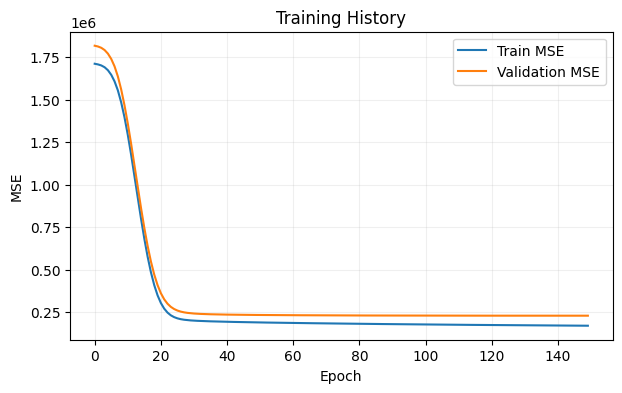

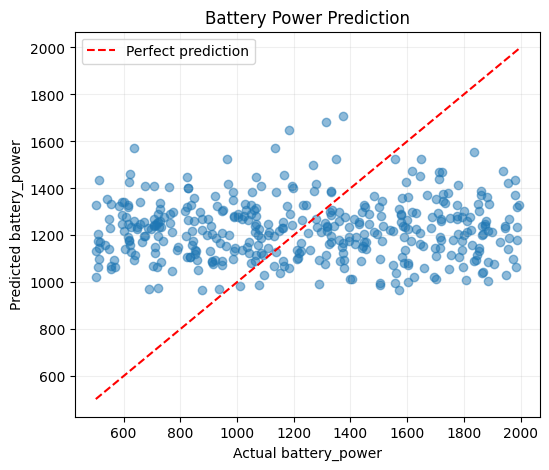

In [7]:
plt.figure(figsize=(7,4))
plt.plot(history.history['loss'], label='Train MSE')
plt.plot(history.history['val_loss'], label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training History'); plt.legend(); plt.grid(alpha=0.2); plt.show()

plt.figure(figsize=(6,5))
plt.scatter(y_test, y_pred, alpha=0.5)
lo = min(y_test.min(), y_pred.min()); hi = max(y_test.max(), y_pred.max())
plt.plot([lo,hi],[lo,hi], 'r--', label='Perfect prediction')
plt.xlabel('Actual battery_power'); plt.ylabel('Predicted battery_power')
plt.title('Battery Power Prediction'); plt.legend(); plt.grid(alpha=0.2); plt.show()